# 20 · Phase 2: video, memory and tracking on KAIST

Phase 2 turns the still-image detector into a video analyser. It trains CFFM-Net and the concat baseline on KAIST, the standard visible-thermal pedestrian benchmark (95,000 aligned frames at 20 fps), adds the Temporal State Memory and trains it on clips with the detector frozen, then measures what the memory buys: log-average miss rate on the standard test set, clean and while a camera is failing, and MOTA and IDF1 when tracking with ByteTrack.

| | |
|---|---|
| **Kaggle settings** | Accelerator **GPU T4 x2**, Internet **on** |
| **Inputs to attach** | `cffm-net-pilot`, `adlteam/kaist-dataset` (frames) and `arnb007/annotation-of-kaist-dataset` (vbb) |
| **Expected runtime** | about 9 hours on 2 x T4; every step resumes after a restart |
| **Produces** | `results/phase2/`: miss-rate and tracking tables, memory weights, failure boards and a clip |

In [1]:
import glob, shutil, subprocess, sys
from pathlib import Path

ON_KAGGLE = Path("/kaggle/working").exists()
if ON_KAGGLE:
    PROJECT = Path("/kaggle/working/cffm-net-pilot")
    if not PROJECT.exists():
        hits = [Path(p).parent for k in range(1, 6) for p in glob.glob("/kaggle/input" + "/*" * k + "/pyproject.toml")
                if (Path(p).parent / "src" / "cffm").is_dir()]
        hits.sort(key=lambda h: any((h.parent / d).exists() for d in ("runs", "data")))
        zips = [Path(p) for k in range(1, 5) for p in glob.glob("/kaggle/input" + "/*" * k + ".zip")
                if "cffm" in Path(p).name]
        if hits:
            shutil.copytree(hits[0], PROJECT, copy_function=shutil.copyfile)
        elif zips:
            shutil.unpack_archive(str(zips[0]), "/kaggle/working")
        assert PROJECT.exists(), "Add the 'cffm-net-pilot' dataset (the uploaded zip) as an input to this notebook."
        for p in [PROJECT, *PROJECT.rglob("*")]:
            p.chmod(p.stat().st_mode | 0o200)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.171",
                    "faster-coco-eval>=1.6.7", "cloudpickle", "pytest", "lap>=0.5.12", "imageio-ffmpeg", "motmetrics"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "-e", str(PROJECT)], check=True)
else:
    PROJECT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src" / "cffm").is_dir())
sys.path.insert(0, str(PROJECT / "src"))

import cffm
from cffm import env as cenv, pipeline
print("cffm", cffm.__version__, "imported from", Path(cffm.__file__).parent)
env = cenv.setup()
plan = pipeline.load_plan(env.project)

cffm 0.1.0 imported from C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\src\cffm


platform=local  device=0  gpus=[NVIDIA GeForce RTX 4050 Laptop GPU (6 GB)]  scan=torch
project=C:\Users\roshh\Desktop\computer vision\cffm-net-pilot
data=C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\processed
runs=C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\runs


In [2]:
from pathlib import Path
import json, shutil, time
import cv2, numpy as np, pandas as pd, torch
from cffm import kaist, video, faults, hud, showcase as sc
from cffm.train import _load

INPUT = [Path("/kaggle/input")] if ON_KAGGLE else [env.project / "data" / "raw"]
IMG_ROOT, ANN_ROOT = kaist.find_roots(INPUT)
dev = "cuda:0" if torch.cuda.is_available() else "cpu"
out = env.project / "results" / "phase2"
out.mkdir(parents=True, exist_ok=True)
for f in Path("/kaggle/input").glob("**/results/phase2/*"):
    if f.suffix in (".json", ".pt") and not (out / f.name).exists():
        shutil.copy(f, out / f.name)
print("KAIST images:", IMG_ROOT, "| annotations:", ANN_ROOT, "| device:", dev)

KAIST images: C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\raw\kaist\extracted\kaist-cvpr15\images | annotations: C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\raw\kaist_ann\annotations | device: cuda:0


## 1. The benchmark

Training uses sets 00 to 05 and testing sets 06 to 11, the standard split. Stills for detector training are every 4th training frame; the still-image test set is the standard every 20th frame. The headline metric is the log-average miss rate over 10^-2 to 10^0 false positives per image on the *reasonable* subset (people at least 55 px tall, at most partly occluded): lower is better.

In [3]:
ds = plan["datasets"]["kaist"]
kdata = env.data / "kaist"
if not (kdata / "data_paired.yaml").exists():
    counts = kaist.convert(IMG_ROOT, ANN_ROOT, kdata, train_stride=ds["train_stride"], test_stride=ds["test_stride"])
    print("converted", counts)
train_seqs = kaist.sequences(IMG_ROOT, ANN_ROOT, kaist.TRAIN_SETS)
test_seqs = kaist.sequences(IMG_ROOT, ANN_ROOT, kaist.TEST_SETS)
rows = [{"split": n, "sequences": len(s), "frames": sum(len(q.frames) for q in s),
         "person boxes": sum(1 for q in s for f in q.boxes for b in f if b.label == "person"),
         "reasonable": sum(1 for q in s for f in q.boxes for b in f if b.reasonable),
         "night sequences": sum(not q.daytime for q in s)} for n, s in (("train", train_seqs), ("test", test_seqs))]
pd.DataFrame(rows)

converted {'train': 12555, 'val': 2262}


,split,sequences,frames,person boxes,reasonable,night sequences
0,train,25,50184,41472,24154,5
1,test,16,45140,44680,24532,5


## 2. Train the detectors

CFFM-Net v2 and the concat baseline with the same recipe: COCO-pretrained YOLO26-n backbones, modality dropout 0.15, 25 epochs, two GPUs. Finished runs are reused.

In [4]:
for s in pipeline.runs_for(plan, "20"):
    pipeline.train_from_spec(s, env)
ckpts = pipeline.find_checkpoints(env)
models = {"concat": _load(ckpts["kaist_concat_md"]).to(dev), "cffm": _load(ckpts["kaist_cffm_v2"]).to(dev)}

[kaist_cffm_v2] already trained, reusing C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\runs\kaist_cffm_v2\weights\best.pt


Ultralytics 8.4.171  Python-3.12.10 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)


cffm-net-n-v2 summary: 285 layers, 5,887,843 parameters, 0 gradients, 15.5 GFLOPs


WARNING val: Slow image access detected (ping: 0.00.0 ms, read: 30.96.6 MB/s, size: 296.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips


val: Scanning C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\processed\kaist\labels\visible\val... 48 images, 23 backgrounds, 0 corrupt: 2% ──────────── 48/2262 139.4it/s 0.1s<15.9s

val: Scanning C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\data\processed\kaist\labels\visible\val... 103 images, 42 backgrounds, 0 corrupt: 4% ╸─────────── 103/2262 239.8it/s 0.2s<9.0s

... (659 outputs left out)

 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.906


 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.384


Results saved to C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\runs\eval\kaist_concat_md


[kaist_concat_md] AP50-95 0.2468  AP50 0.6253  AP_s 0.0819


## 3. Still-image results

Each test frame on its own, no memory: the KAIST table every paper reports.

In [5]:
cache = out / "stills.json"
if cache.exists():
    stills = json.loads(cache.read_text())
else:
    stills = {n: video.evaluate_sequences(m, test_seqs, stride=20, memory=False, device=dev) for n, m in models.items()}
    cache.write_text(json.dumps(stills, indent=2))
(pd.DataFrame(stills).T[["MR_all", "MR_day", "MR_night", "AP50_all"]] * 100).round(2)

,MR_all,MR_day,MR_night,AP50_all
concat,19.80,19.94,18.61,84.55
cffm,20.32,21.12,18.55,83.88


## 4. Train the Temporal State Memory

One memory block per fusion level, zero-initialised so the detector starts exactly as trained. The detector is frozen; only the memory learns, by backpropagation through six frames at 10 fps with the detection loss on every frame. Half the clips lose or corrupt a camera part-way through, so the memory learns to carry what it saw across the failure.

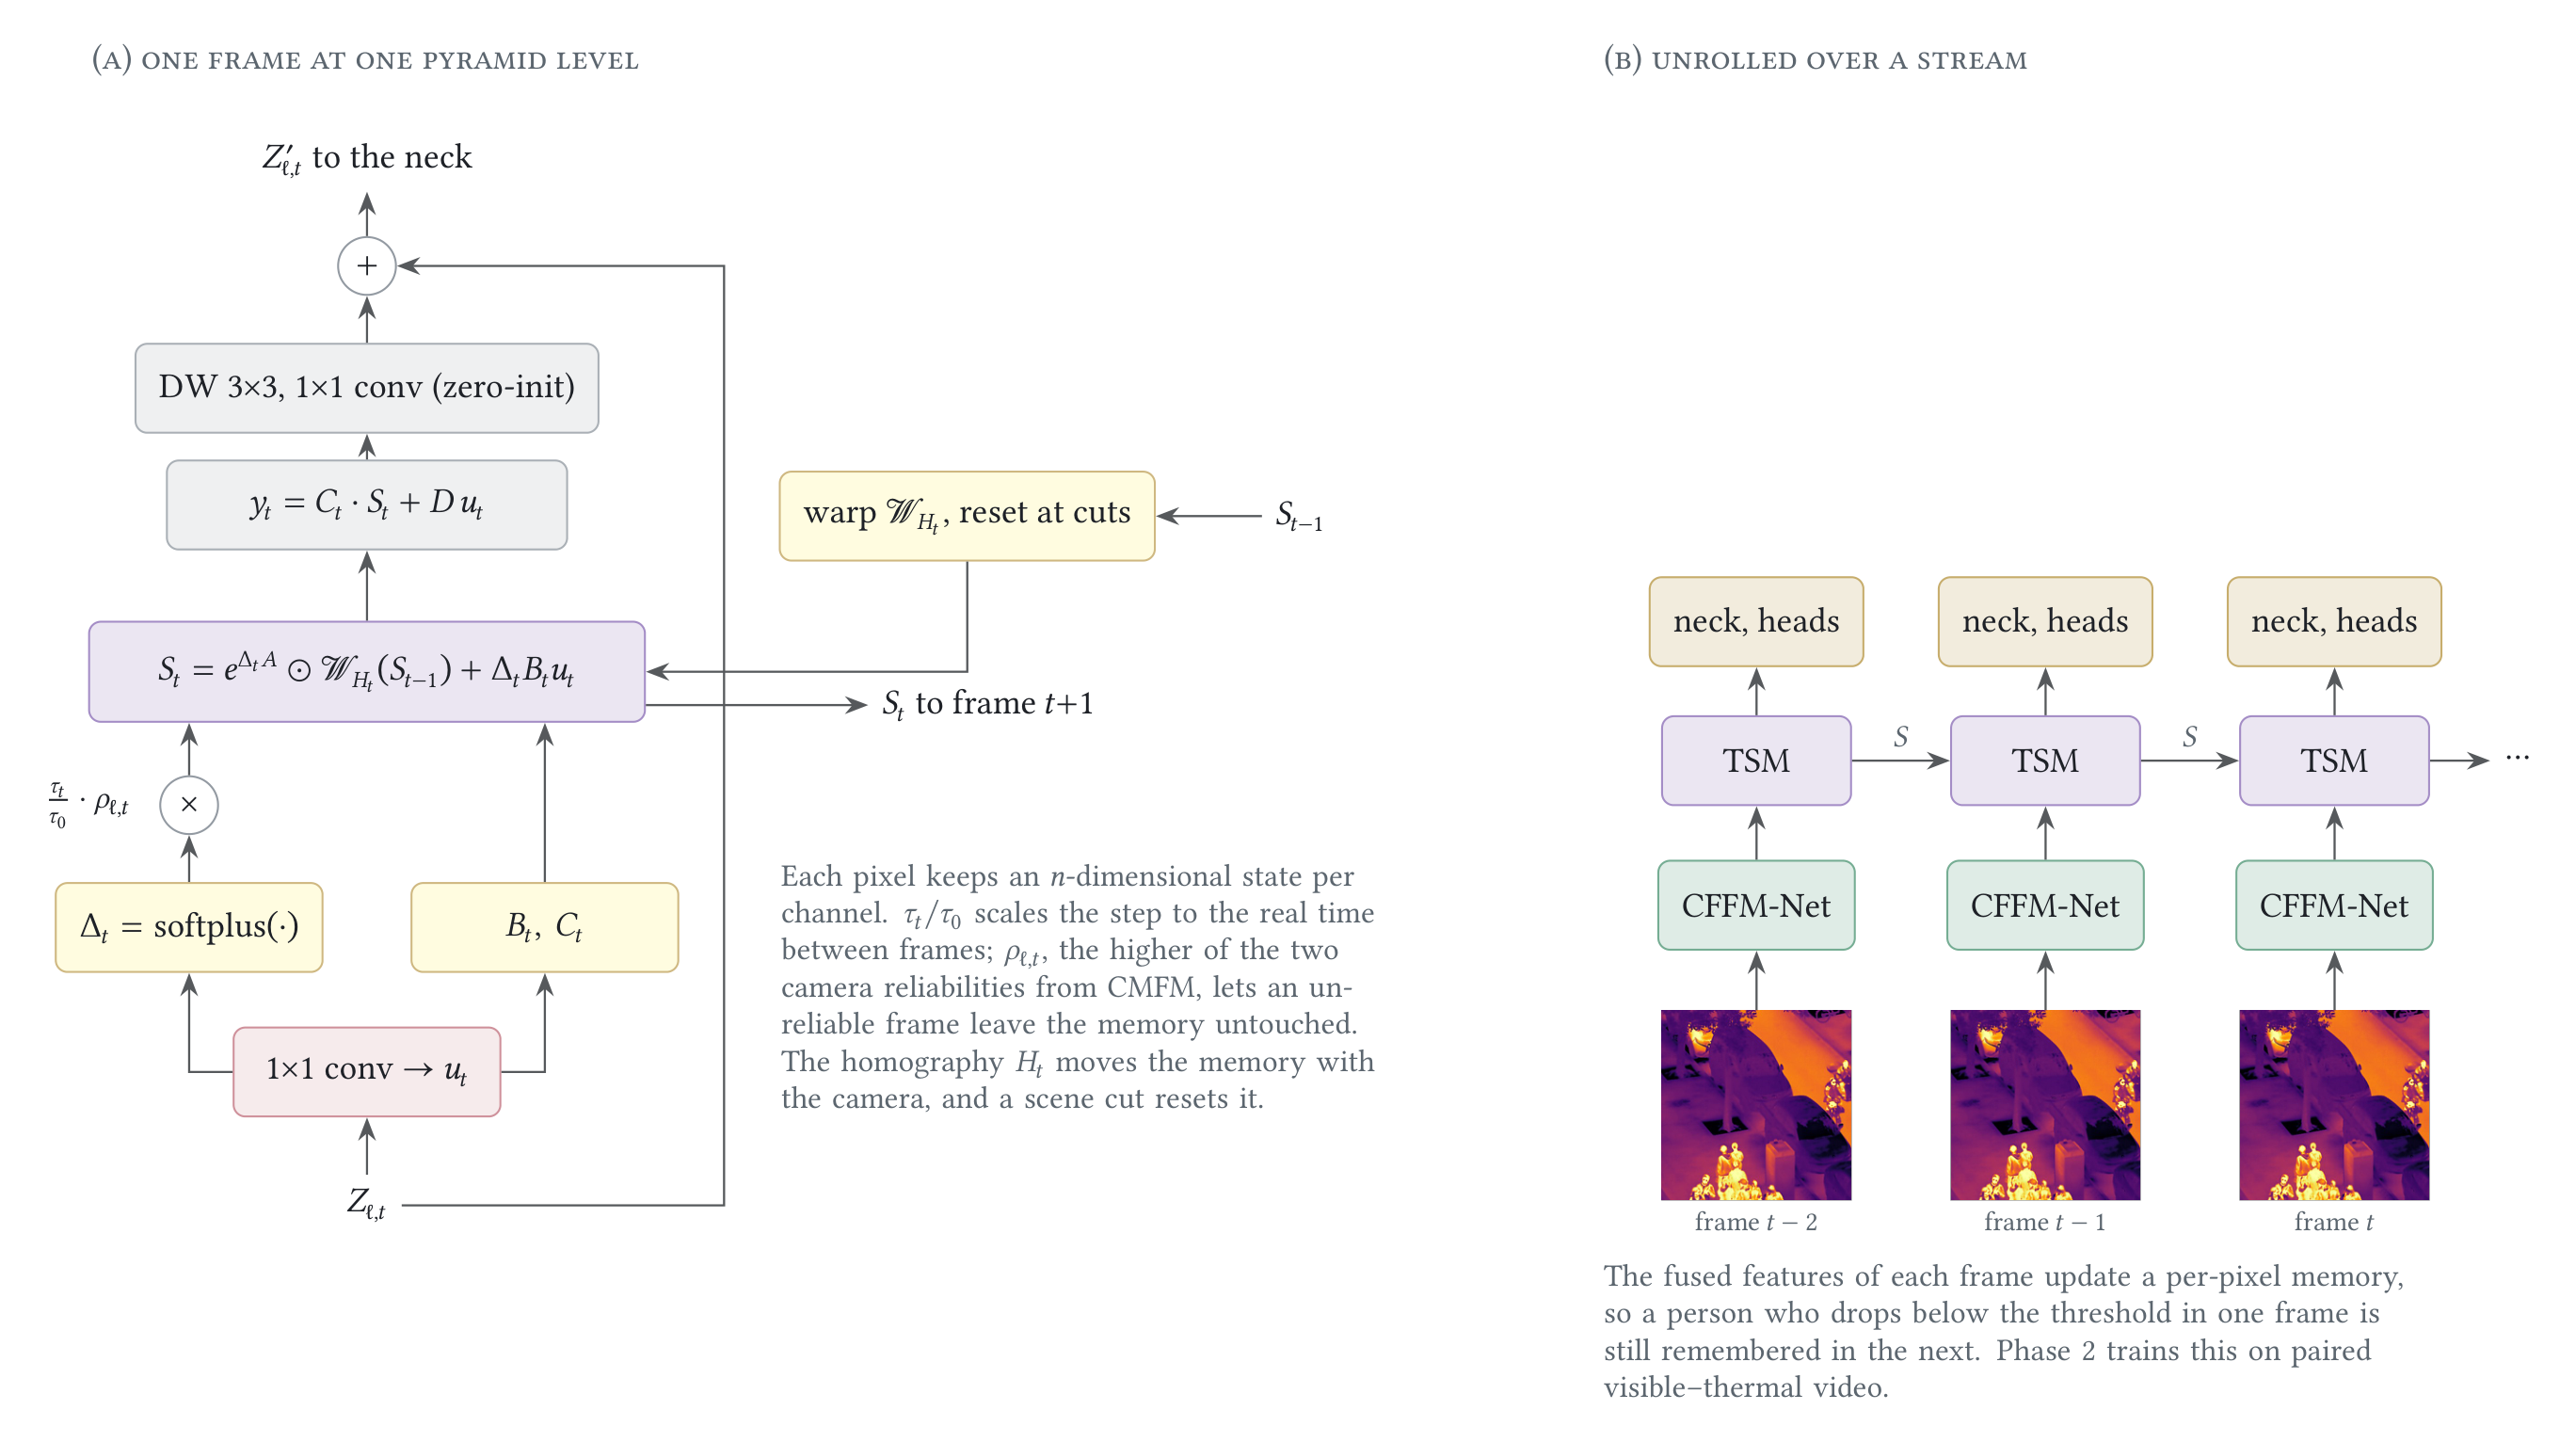

In [6]:
from IPython.display import Image, display
for name in ('fig_tsm',):
    f = env.project / "docs" / "figures" / f"{name}.png"
    if f.exists():
        display(Image(filename=str(f), width=820))
    else:
        print("missing", f)

In [7]:
cffm = models["cffm"]
mem_path = out / "memory.pt"
cffm.attach_memory()
saved = [m for m in [mem_path, *Path("/kaggle/input").glob("**/results/phase2/memory.pt")] if m.exists()]
saved = [m for m in saved if all(torch.isfinite(v).all() for v in torch.load(m, map_location="cpu").values())]
if saved:
    cffm.memory.load_state_dict(torch.load(saved[0], map_location=dev))
    print("memory loaded from", saved[0])
else:
    hist = video.train_memory(cffm, train_seqs, epochs=3, T=6, stride=2, batch=4, lr=5e-4, workers=4, device=dev)
    torch.save(cffm.memory.state_dict(), mem_path)
    pd.DataFrame(hist, columns=["step", "loss"]).plot(x="step", y="loss", figsize=(7, 3), legend=False,
                                                       title="memory training loss")
print("memory parameters:", sum(p.numel() for p in cffm.memory.parameters()))

memory loaded from C:\Users\roshh\Desktop\computer vision\cffm-net-pilot\results\phase2\memory.pt
memory parameters: 132912


## 5. What the memory buys

The test sequences run causally at 10 fps, carrying state frame to frame, and are scored on the standard every-20th-frame grid. Each failure repeats: 4 s healthy, then 4 s failed. *Failed* scores only frames inside a failure; *flagged* means the stream monitor reported the dropped camera. The detector weights are identical in every row; only the memory differs.

In [8]:
SCHEDULES = {"clean": None,
             "thermal lost": video.periodic("thermal_drop", 3, on=80, off=80),
             "visible dark": video.periodic("visible_dark", 3, on=80, off=80),
             "thermal noise": video.periodic("thermal_noise", 3, on=80, off=80)}
cache = out / "memory.json"
mem = json.loads(cache.read_text()) if cache.exists() else {}
for name, sched in SCHEDULES.items():
    for flagged in ([False, True] if name == "thermal lost" else [False]):
        for use in (False, True):
            key = f"{name}{' (flagged)' if flagged else ''} | {'memory' if use else 'image'}"
            if key in mem:
                continue
            t0 = time.time()
            mem[key] = video.evaluate_sequences(cffm, test_seqs, stride=2, memory=use, schedule=sched,
                                                flags=flagged, device=dev)
            cache.write_text(json.dumps(mem, indent=2))
            print(f"{key:40s} MR {mem[key]['MR_all'] * 100:5.2f}  ({(time.time() - t0) / 60:.1f} min)")
rows = []
for k in sorted({k.split(" | ")[0] for k in mem}):
    a, b = mem[f"{k} | image"], mem[f"{k} | memory"]
    for col in ("MR_all", "MR_failed", "MR_night"):
        if col in a:
            rows.append({"condition": k, "metric": col, "image": a[col] * 100, "memory": b[col] * 100,
                         "change (pts, lower is better)": (b[col] - a[col]) * 100})
pd.DataFrame(rows).round(2)

,condition,metric,image,memory,"change (pts, lower is better)"
0,clean,MR_all,20.32,19.80,-0.53
1,clean,MR_night,18.55,18.38,-0.17
2,thermal lost,MR_all,26.24,25.90,-0.34
3,thermal lost,MR_failed,31.57,32.29,0.72
4,thermal lost,MR_night,34.13,35.07,0.94
5,thermal lost (flagged),MR_all,26.26,25.88,-0.38
6,thermal lost (flagged),MR_failed,31.61,32.28,0.67
7,thermal lost (flagged),MR_night,34.12,35.18,1.06
8,thermal noise,MR_all,51.58,34.07,-17.51
9,thermal noise,MR_failed,75.40,45.91,-29.49


## 6. Tracking

ByteTrack on every frame of four test sequences (two by day, two by night) at 20 fps, with and without memory, clean and with the thermal camera failing. MOTA and IDF1 against KAIST's track ids.

In [9]:
cache = out / "tracking.json"
trk = json.loads(cache.read_text()) if cache.exists() else {}
wanted = ("set06/V000", "set08/V000", "set09/V000", "set10/V001")
pick = [s for s in test_seqs if s.name in wanted] or test_seqs[:4]
for name in ("clean", "thermal lost"):
    for use in (False, True):
        key = f"{name} | {'memory' if use else 'image'}"
        if key in trk:
            continue
        per = []
        for s in pick:
            tracks = video.track_sequence(cffm, s, memory=use, schedule=SCHEDULES[name], device=dev, flags=True)
            per.append({"seq": s.name, **video.mot_metrics(tracks, s)})
        trk[key] = per
        cache.write_text(json.dumps(trk, indent=2))
summary = {k: pd.DataFrame(v)[["mota", "idf1", "num_switches"]].mean().to_dict() for k, v in trk.items()}
pd.DataFrame(summary).T.round(3)

,mota,idf1,num_switches
clean | image,0.445,0.643,8.75
clean | memory,0.425,0.613,8.25
thermal lost | image,0.353,0.536,10.25
thermal lost | memory,0.347,0.507,9.50


## 7. The Machine's view of a failure

A night sequence at the moment the thermal camera is cut. Top of each board: image mode; bottom: with memory.

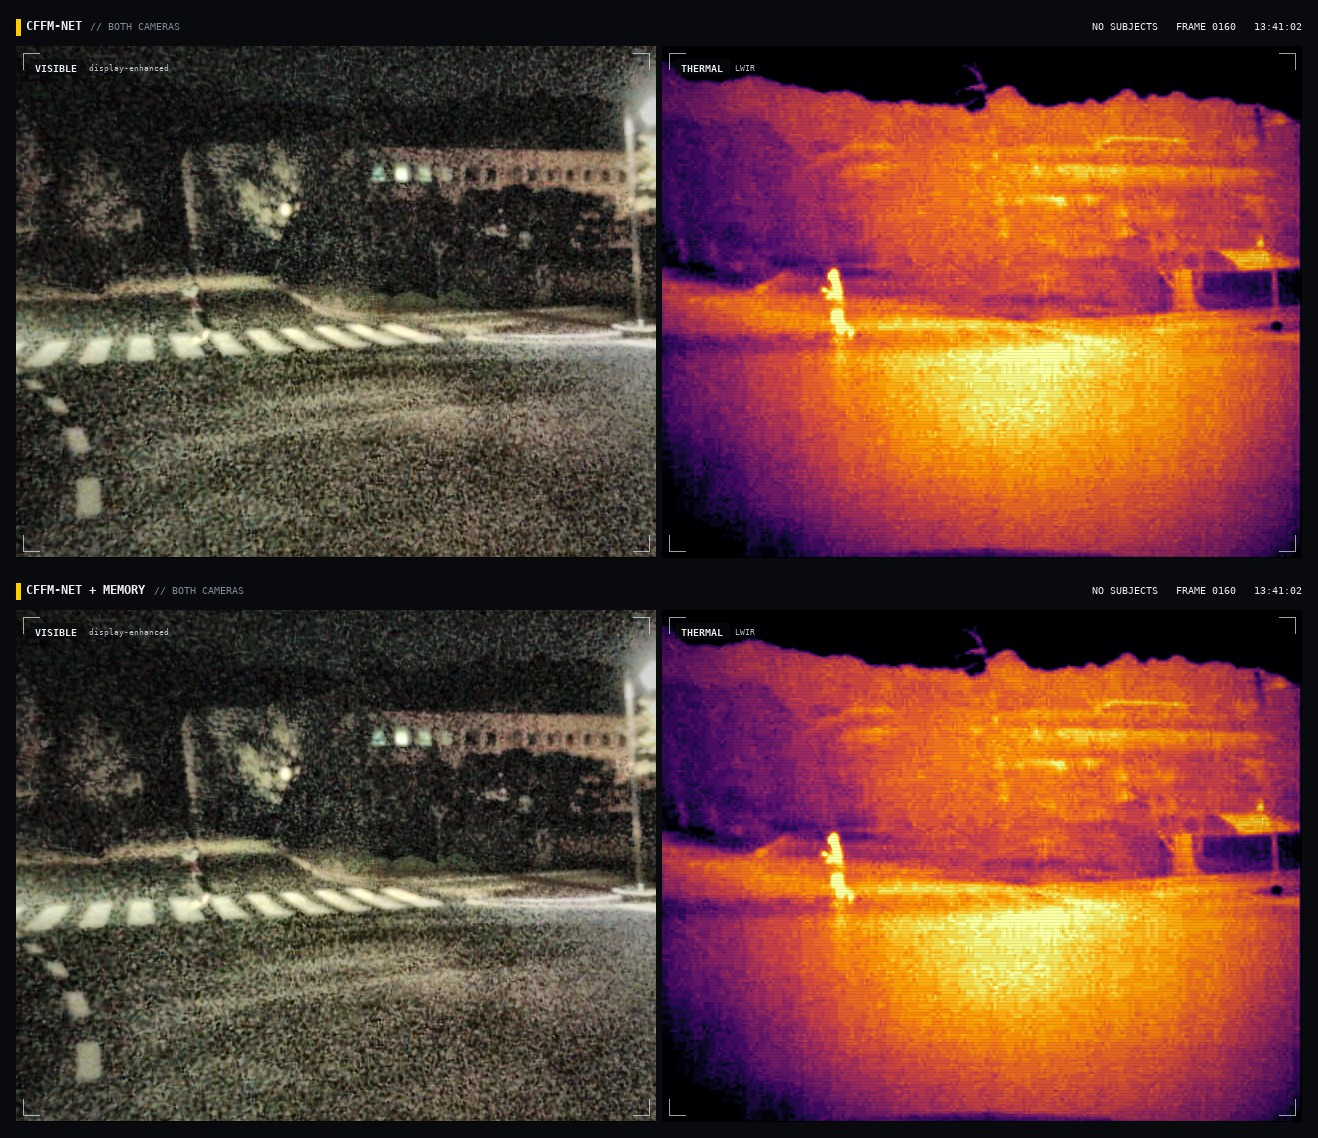

In [10]:
seq = next(s for s in test_seqs if not s.daytime)
active = video.periodic("thermal_drop", 3, on=80, off=80)[0]
boards = []
cffm.reset_memory()
for i in range(40, 240, 2):
    x = video.to_tensor(video.read_frame(seq.frames[i]))[None].to(dev)
    if active(i):
        x = faults.apply(x, "thermal_drop", 3)
    img = (x[0].permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    tiles = []
    for use in (False, True):
        cffm.memory_on = use
        with torch.no_grad():
            d = video.detect(cffm, x, conf=0.3)[0]
        tiles.append(hud.render(img, d, {0: "person"}, frame=i, panel_w=640,
                                title="CFFM-NET + MEMORY" if use else "CFFM-NET",
                                subtitle="THERMAL LOST" if active(i) else "BOTH CAMERAS", panels=("visible", "thermal")))
    boards.append(hud.grid(tiles, cols=1))
hud.save_video(boards, out / "failure_memory.mp4", fps=10, width=1280)
sc.show(boards[60])

In [11]:
(out / "phase2_summary.json").write_text(json.dumps({"stills": stills, "memory": mem, "tracking": summary},
                                                    indent=2, default=float))
print("saved", sorted(p.name for p in out.iterdir()))

saved ['failure_memory.mp4', 'memory.json', 'memory.pt', 'phase2_summary.json', 'stills.json', 'tracking.json']


In [12]:
if env.platform == "kaggle":
    shutil.rmtree(env.data, ignore_errors=True)